# Margins and hidden layers: do an SVM or a neural network find more churners?

**Governing question.** Softmax regression, k-NN, trees, forests, and boosting all reach about the same ranking quality on Waze churn (average precision ≈ 0.39 at best). Two course families remain: a **linear support vector machine**, which fits a maximum-margin boundary instead of probabilities, and a **neural network**, which can learn non-linear combinations of features through hidden layers. Does either rank churners better, or do they confirm that the limit is in the data?

**Intended user.** The Waze product manager choosing which users to contact. A better ranking means more churners reached for the same outreach budget.

**Evidence rules.** Development users only, the same cross-validation folds as notebooks 02–05. The sealed test set stays closed until model selection.

**Road map.** §1 data → §2 mathematics → §3 verification → §4 the SVM, and why class weights decide everything → §5 the neural network → §6 paired comparison → §7 failure analysis → §8 decision.

## 1. Data boundary

Unchanged (see `docs/DATASET_CARD.md`): 14,299 labeled synthetic Waze users, `churned` = 1 for 17.7%, the 11 raw features, and the same-month timing caveat. Both models use distances or gradient steps, so every pipeline standardizes features inside each fold.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import average_precision_score
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from dsm_project.algorithms import create_student_algorithm
from dsm_project.algorithms.student.neural_network import loss_and_gradients
from dsm_project.algorithms.student.svm import hinge_objective
from dsm_project.config import load_config
from dsm_project.data.waze import WazeChurnAdapter
from dsm_project.experiments import split_supervised_task
from dsm_project.visualization import OUTCOME_PALETTE, set_theme

set_theme()
config = load_config(Path("configs/waze.toml"))
dataset = WazeChurnAdapter().load(config)
split = split_supervised_task(dataset, config, task_name="classification")
dev_x, dev_y = split.train_features, split.train_targets
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=438)


def standardized(model):
    return make_pipeline(StandardScaler(), model)


def cv_ap(model):
    return cross_val_score(model, dev_x, dev_y, cv=cv, scoring="average_precision")


print(f"development users: {len(dev_x):,} | churn rate {dev_y.mean():.3f}")

development users: 10,724 | churn rate 0.177


## 2. The mathematics

### 2.1 Linear SVM

Labels become $y_i \in \{-1, +1\}$ (churned = +1) and a user is scored by $f(x) = w^\top x + b$. The SVM minimizes the **hinge loss** plus an L2 penalty:

$$
J(w, b) = \frac{\lambda}{2}\lVert w\rVert^2 + \frac{1}{S}\sum_{i=1}^n s_i \max\bigl(0,\, 1 - y_i f(x_i)\bigr),
$$

with optional row weights $s_i$ and $S = \sum_i s_i$. The hinge is **zero** for users classified correctly *with a margin* ($y_i f(x_i) \ge 1$), so only users on or inside the margin, the support vectors, shape the boundary. The hinge has a kink at the margin, so training uses a **subgradient**: for the set $M$ of users with $y_i f(x_i) < 1$,

$$
g_w = \lambda w - \frac{1}{S}\sum_{i\in M} s_i y_i x_i, \qquad g_b = -\frac{1}{S}\sum_{i \in M} s_i y_i .
$$

Subgradient steps do not lower $J$ every time, so the step shrinks as $\eta_0/\sqrt{t}$ and the best iterate is kept. An SVM outputs a *score*, not a probability, and the score is what ranking metrics use.

**Contrast with softmax regression.** Logistic (softmax) loss $\log(1 + e^{-y f(x)})$ is never exactly zero: it keeps rewarding a more confident correct score. The hinge stops caring once a user is past the margin. §4 shows why this difference matters on imbalanced data.

### 2.2 Neural network

A neural network stacks layers $Z_\ell = A_{\ell-1}W_\ell + b_\ell$ with ReLU activations $A_\ell = \max(0, Z_\ell)$ and a softmax output. Softmax regression is the special case with no hidden layer; hidden layers let the model combine features non-linearly. It minimizes cross-entropy plus $\frac{\alpha}{2}\sum_\ell \lVert W_\ell\rVert^2$. **Backpropagation** computes all gradients in one backward pass, starting from $\Delta_L = (P - Y)/m$ and using

$$
\nabla_{W_\ell} J = A_{\ell-1}^\top \Delta_\ell + \alpha W_\ell, \qquad
\Delta_{\ell-1} = (\Delta_\ell W_\ell^\top) \odot \mathbb{1}[Z_{\ell-1} > 0].
$$

Weights start from He initialization ($\mathcal{N}(0, 2/\text{fan-in})$, which keeps ReLU signals at a stable scale), and training uses shuffled mini-batches with the Adam optimizer.

## 3. Student implementation and verification

| Component | Package location | Key evidence (`tests/test_svm_neural_network.py`) |
| --- | --- | --- |
| `LinearSVM` | `student/svm.py` | hinge and subgradient by hand; maximum margin on two points ($w = 1$, $b = 0$); objective within 0.01% of scikit-learn's exact `SVC` on the same objective; balanced weights flag more of the rare class |
| `NeuralNetworkClassifier` | `student/neural_network.py` | backpropagation equals finite differences for every weight and bias of a 3-layer network; learns XOR where a linear model cannot; reproducible; accuracy comparable to scikit-learn's `MLPClassifier` |

Two live checks on Waze data. First, the SVM reaches the exact optimum of its objective on a 3,000-user sample, using scikit-learn's exact solver, whose `C` matches our $\lambda$ as $C = 1/(n\lambda)$:

In [2]:
scaler = StandardScaler().fit(dev_x)
sample = np.random.default_rng(0).choice(len(dev_y), 3000, replace=False)
x_sample = scaler.transform(dev_x.iloc[sample])
y_sample = dev_y.to_numpy()[sample]
signed = np.where(y_sample == 1, 1.0, -1.0)

check = []
for weighting in (None, "balanced"):
    student = create_student_algorithm("linear_svm", l2_penalty=0.01, class_weight=weighting,
                                       max_iterations=5000).fit(x_sample, y_sample)
    exact = SVC(kernel="linear", C=1 / (len(y_sample) * 0.01), class_weight=weighting).fit(
        x_sample, y_sample)
    weights = student._row_weights(student.classes_, (y_sample == 1).astype(int))
    exact_objective = hinge_objective(exact.coef_[0], exact.intercept_[0], x_sample, signed,
                                      0.01, weights)[0]
    check.append({"class weights": weighting or "none",
                  "student objective": student.objective_, "exact objective": exact_objective,
                  "student |w|": np.linalg.norm(student.coef_),
                  "exact |w|": np.linalg.norm(exact.coef_)})
display(pd.DataFrame(check).set_index("class weights").round(5))

,student objective,exact objective,student |w|,exact |w|
class weights,,,,
none,0.36176,0.36135,0.00294,0.00106
balanced,0.67065,0.67065,0.79289,0.79463


In both settings the student objective is within about 0.1% of the exact optimum. Look at the weight norms, though: **without class weights, the exact solution itself has almost no weights** ($\lVert w\rVert \approx 0.001$). §4 explains why. This is a property of the SVM objective, not a training failure.

Second, a live gradient check of backpropagation on a small random network:

In [3]:
rng = np.random.default_rng(1)
small_x = rng.normal(size=(6, 4))
small_y = np.eye(2)[rng.integers(0, 2, size=6)]
layers = [(rng.normal(size=(4, 5)), rng.normal(size=5)), (rng.normal(size=(5, 2)), rng.normal(size=2))]
_, gradients = loss_and_gradients(layers, small_x, small_y, alpha=0.01)
worst, h = 0.0, 1e-6
for (weights, _), (analytic, _) in zip(layers, gradients, strict=True):
    for index in np.ndindex(weights.shape):
        original = weights[index]
        weights[index] = original + h
        up, _ = loss_and_gradients(layers, small_x, small_y, alpha=0.01)
        weights[index] = original - h
        down, _ = loss_and_gradients(layers, small_x, small_y, alpha=0.01)
        weights[index] = original
        worst = max(worst, abs((up - down) / (2 * h) - analytic[index]))
print(f"max |backprop − finite difference| over all weights: {worst:.1e}")

max |backprop − finite difference| over all weights: 4.3e-10


Backpropagation matches the numerical derivative to about $10^{-10}$, so the derivation in §2.2 is implemented correctly.

## 4. The SVM, and why class weights decide everything

We cross-validate the SVM over the penalty $\lambda$, with and without balanced class weights. Balanced weights give each churner a weight of $n/(2 n_{\text{churned}})$, so churners and retained users carry equal total weight.

CV AP      sd
λ     class weights                
0.001 none           0.2730  0.0162
      balanced       0.3908  0.0186
0.010 none           0.2724  0.0165
      balanced       0.3901  0.0188
0.100 none           0.2712  0.0158
      balanced       0.3887  0.0189

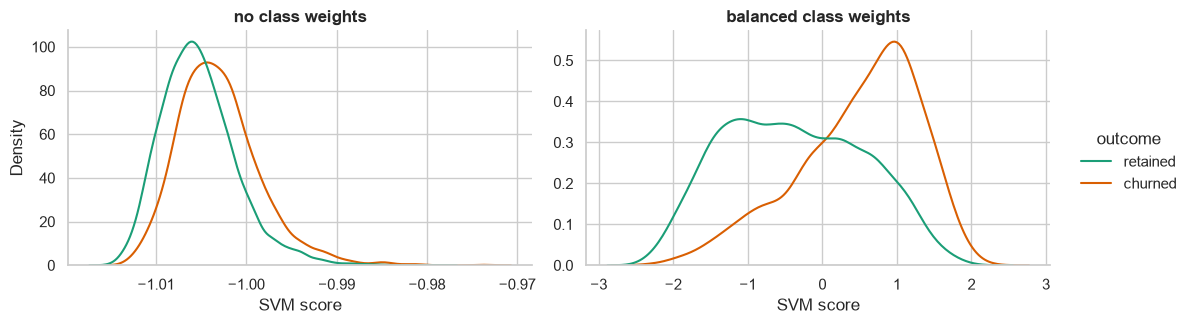

share of users the unweighted SVM flags as churn: 0.0%


In [4]:
svm_rows = []
for penalty in (0.001, 0.01, 0.1):
    for weighting in (None, "balanced"):
        scores = cv_ap(standardized(create_student_algorithm(
            "linear_svm", l2_penalty=penalty, class_weight=weighting)))
        svm_rows.append({"λ": penalty, "class weights": weighting or "none",
                         "CV AP": scores.mean(), "sd": scores.std()})
display(pd.DataFrame(svm_rows).set_index(["λ", "class weights"]).round(4))

collapsed = standardized(create_student_algorithm("linear_svm", l2_penalty=0.01)).fit(dev_x, dev_y)
weighted = standardized(create_student_algorithm(
    "linear_svm", l2_penalty=0.01, class_weight="balanced")).fit(dev_x, dev_y)
scores = pd.concat([
    pd.DataFrame({"SVM score": model.decision_function(dev_x), "model": label,
                  "outcome": dev_y.map({0: "retained", 1: "churned"}).to_numpy()})
    for label, model in (("no class weights", collapsed), ("balanced class weights", weighted))
])
grid = sns.displot(data=scores, x="SVM score", hue="outcome", col="model",
                   palette=OUTCOME_PALETTE, kind="kde", common_norm=False,
                   facet_kws={"sharex": False, "sharey": False}, height=3.4, aspect=1.6)
grid.set_titles("{col_name}")
plt.show()
print("share of users the unweighted SVM flags as churn:",
      f"{(collapsed.decision_function(dev_x) > 0).mean():.1%}")

**Insights.**

- **Without class weights the SVM collapses.** It flags no one, its weights are almost zero, and its ranking is far worse than every other model (AP ≈ 0.27, against 0.18 for random ranking and 0.39 for softmax). Every user's score falls in a narrow band between about −1.01 and −0.98, with the two outcomes nearly on top of each other.
- **Why:** with 18% churners and heavy overlap between the classes, any boundary that catches churners also puts many retained users inside the margin. Because the hinge charges nothing for users already beyond the margin, the cheapest solution is to push every user to the retained side ($b \approx -1$, $w \approx 0$) and pay hinge loss only on the churners. The exact solver in §3 reaches the same collapsed solution, so this is the true optimum of the objective.
- **With balanced weights** churners count as much as retained users, the boundary moves into the overlap, and the SVM ranks as well as softmax regression (AP ≈ 0.39) for every $\lambda$.

**Main takeaway: for an imbalanced problem like churn, the loss function matters.** Softmax regression's log-loss keeps rewarding better rankings, so class weights barely changed it (notebook 02). The hinge loss needs them.

By the selection rule (ties within 0.005 go to stronger regularization), the SVM candidate is **balanced, $\lambda = 0.1$**.

## 5. The neural network

We vary the architecture (one hidden layer of 16 or 64 units, or two layers of 32 and 16) and the weight penalty $\alpha$.

CV AP      sd
hidden layers α                     
(16,)         0.0001  0.3793  0.0175
              0.0100  0.3919  0.0151
(64,)         0.0001  0.3563  0.0126
              0.0100  0.3916  0.0142
(32, 16)      0.0001  0.3562  0.0170
              0.0100  0.3929  0.0157

(16,), α = 0.01: stopped after 112 epochs, training loss 1.069 → 0.412


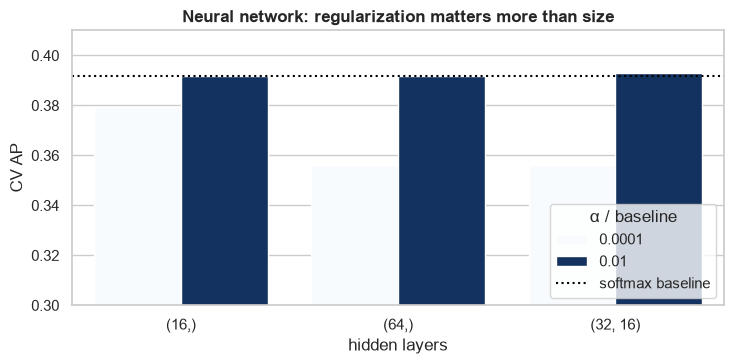

In [5]:
nn_rows = []
for hidden in ((16,), (64,), (32, 16)):
    for alpha in (1e-4, 1e-2):
        scores = cv_ap(standardized(create_student_algorithm(
            "neural_network", hidden_layer_sizes=hidden, alpha=alpha, random_state=0)))
        nn_rows.append({"hidden layers": str(hidden), "α": alpha,
                        "CV AP": scores.mean(), "sd": scores.std()})
nn_table = pd.DataFrame(nn_rows)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
sns.barplot(data=nn_table, x="hidden layers", y="CV AP", hue="α", palette="Blues", ax=ax)
ax.axhline(0.3916, color="black", linestyle=":", label="softmax baseline")
ax.set(ylim=(0.3, 0.41), title="Neural network: regularization matters more than size")
ax.legend(title="α / baseline", loc="lower right")
plt.tight_layout()
display(nn_table.set_index(["hidden layers", "α"]).round(4))

curve_model = standardized(create_student_algorithm(
    "neural_network", hidden_layer_sizes=(16,), alpha=1e-2, random_state=0)).fit(dev_x, dev_y)
print(f"(16,), α = 0.01: stopped after {curve_model[-1].n_epochs_} epochs, "
      f"training loss {curve_model[-1].loss_curve_[0]:.3f} → {curve_model[-1].loss_curve_[-1]:.3f}")

**Insights.**

- **Regularization matters more than size.** With weak regularization ($\alpha = 10^{-4}$), larger networks overfit: AP falls to about 0.36 for the 64-unit and two-layer networks. With $\alpha = 0.01$, every architecture recovers to about 0.39, the softmax level.
- Extra capacity buys nothing here. Once the network is kept from memorizing noise, it behaves like a linear model, consistent with notebook 04's finding that the churn signal is additive.

By the selection rule (ties within 0.005 go to the simpler model), the network candidate is **one hidden layer of 16 units, $\alpha = 0.01$**.

## 6. Paired comparison

The two candidates are compared with softmax regression on the same 15 folds (5 folds × 3 repeats), alongside scikit-learn references with matching settings: an exact-objective linear SVM on the development folds would be too slow, so the SVM reference is `LinearSVC` with hinge loss, and the network reference is `MLPClassifier`.

In [6]:
from sklearn.svm import LinearSVC

repeated = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=438)
n_train = int(len(dev_y) * 0.8)
candidates = {
    "student softmax": create_student_algorithm("softmax_regression", l2_penalty=0.1,
                                                learning_rate=0.5),
    "student SVM (balanced, λ = 0.1)": create_student_algorithm(
        "linear_svm", l2_penalty=0.1, class_weight="balanced"),
    "student network (16,), α = 0.01": create_student_algorithm(
        "neural_network", hidden_layer_sizes=(16,), alpha=1e-2, random_state=0),
    "reference: sklearn LinearSVC (hinge, balanced)": LinearSVC(
        C=1 / (n_train * 0.1), loss="hinge", class_weight="balanced", max_iter=20_000),
    "reference: sklearn MLP (16,), α = 0.01": MLPClassifier(
        (16,), alpha=1e-2, random_state=0, max_iter=500),
}
fold_ap = {name: cross_val_score(standardized(model), dev_x, dev_y, cv=repeated,
                                 scoring="average_precision")
           for name, model in candidates.items()}
base = fold_ap["student softmax"]
summary = pd.DataFrame({
    "mean AP": {k: v.mean() for k, v in fold_ap.items()},
    "gap to softmax": {k: (v - base).mean() for k, v in fold_ap.items()},
    "sd of gap": {k: (v - base).std() for k, v in fold_ap.items()},
    "folds better than softmax": {k: int((v > base).sum()) for k, v in fold_ap.items()},
})
display(summary.round(4))

,mean AP,gap to softmax,sd of gap,folds better than softmax
student softmax,0.3915,0.0000,0.0000,0
"student SVM (balanced, λ = 0.1)",0.3887,-0.0028,0.0032,2
"student network (16,), α = 0.01",0.3914,-0.0001,0.0041,8
"reference: sklearn LinearSVC (hinge, balanced)",0.3886,-0.0030,0.0033,2
"reference: sklearn MLP (16,), α = 0.01",0.3851,-0.0064,0.0074,3


**Reading the comparison.**

- **The network ties softmax regression:** a gap of −0.0001 AP, better on 8 of 15 folds.
- **The balanced SVM is slightly behind:** −0.003 AP, better on only 2 of 15 folds. The gap is about the size of its fold-to-fold spread, so it is at best a tie, never an improvement.
- **The scikit-learn references agree.** `LinearSVC` matches the student SVM to 0.0001 AP, and `MLPClassifier` is within about 0.006 of the student network, so the conclusion does not depend on the student implementations.

## 7. Failure analysis

Do the SVM and the network reach different churners than softmax, especially the active churners every earlier model missed?

In [7]:
oof = {}
for name in ("student softmax", "student SVM (balanced, λ = 0.1)", "student network (16,), α = 0.01"):
    model = standardized(candidates[name])
    method = "decision_function" if "SVM" in name else "predict_proba"
    output = cross_val_predict(model, dev_x, dev_y, cv=cv, method=method)
    oof[name] = output if output.ndim == 1 else output[:, 1]

churners = dev_y.to_numpy() == 1
group = pd.cut(dev_x["activity_days"], [-1, 10, 20, 31],
               labels=["0–10 days", "11–20 days", "21–31 days"]).to_numpy()
reach = {}
for name, scores in oof.items():
    flagged = scores >= np.quantile(scores, 0.8)
    row = pd.Series(flagged[churners]).groupby(group[churners]).mean()
    row["all churners"] = flagged[churners].mean()
    reach[name] = row
display(pd.DataFrame(reach).round(3))
ranks = pd.DataFrame(oof).rank()
print("rank correlation of out-of-fold scores:")
display(ranks.corr().round(3))

,student softmax,"student SVM (balanced, λ = 0.1)","student network (16,), α = 0.01"
0–10 days,0.691,0.703,0.681
11–20 days,0.090,0.050,0.105
21–31 days,0.000,0.000,0.000
all churners,0.452,0.450,0.450


rank correlation of out-of-fold scores:


,student softmax,"student SVM (balanced, λ = 0.1)","student network (16,), α = 0.01"
student softmax,1.000,0.994,0.998
"student SVM (balanced, λ = 0.1)",0.994,1.000,0.989
"student network (16,), α = 0.01",0.998,0.989,1.000


The pattern is the same as for every earlier family. All three models reach about 68–70% of the least-active churners and **none** of the churners active on more than 20 days. Their out-of-fold rankings have rank correlations of 0.99 with each other, so they flag nearly the same users. A margin-based boundary and a non-linear network both meet the same ceiling.

**Failure sources.**

- *Data and task formulation (dominant):* one month of usage cannot separate active users who are about to leave from those who will stay. Seven model families now agree on this.
- *Loss choice:* the unweighted SVM collapses on imbalanced data (§4). This is a real modeling hazard, now documented and tested.
- *Overfitting:* under-regularized networks lose ranking quality (§5).
- *Implementation:* none found. The SVM reaches the exact optimum and backpropagation matches finite differences.

## 8. Conclusion and decision

**Answer.** Neither a maximum-margin model nor a neural network finds churners the linear model misses. With the right settings (balanced class weights for the SVM, strong weight decay for the network), the network **ties** softmax regression at average precision ≈ 0.39 and the SVM comes within 0.003 of it, and both miss the same active churners. Every course family has now been tried, and all meet the same ceiling. That is strong evidence that the limit is the information in one month of usage, not the choice of algorithm.

**Decision.**

- Neither model is promoted over softmax regression, which is as accurate, simpler, faster, and directly interpretable.
- The finalists for model selection stay **softmax regression** and **boosted stumps**. The SVM and network results are kept as evidence that the choice is not leaving accuracy on the table.

**Key lesson for imbalanced problems:** check what the loss function rewards. Log-loss models are robust to class imbalance for *ranking*. Hinge-loss models need class weights or they collapse to "everyone stays".

**Next steps.** Model selection (lecture 16): freeze the finalists and their thresholds, open the sealed test set once, check calibration and the confusion matrix, and save the winning model for the product.